# 3. Main experiments
Every estimator in `ESTIMATORS` on the evaluation DAGs (1–5), plots, then the serial timing run.
Settings come from `1_mle.ipynb` and `2_hyperparameter_tuning.ipynb` (their `config` cells; save those notebooks after editing).

In [4]:
%load_ext autoreload
%autoreload 2

import os
import logging

import numpy as np
import pandas as pd
import torch.nn as nn

from ndbn.experiments import run_experiments
import ndbn.plotting as plotting
from ndbn.plotting import plot_grouped_curves
from ndbn.notebook_config import load_notebook_config

logging.getLogger("pgmpy").setLevel(logging.ERROR)

# settings from 1_mle.ipynb (shared) and 2_hyperparameter_tuning.ipynb (tuning / selection)
globals().update(load_notebook_config("1_mle.ipynb", "2_hyperparameter_tuning.ipynb"))

RESULTS_DIR = "results7-parallel"
CHOSEN_JSON = RESULTS_DIR + "\\chosen_nn_kl.json"
os.makedirs(RESULTS_DIR, exist_ok=True)
RESULTS_CSV = os.path.join(RESULTS_DIR, RESULTS_NAME)      # not 1_mle.ipynb's folder
TIMING_CSV  = os.path.join(RESULTS_DIR, "results_timing.csv")
print("results folder:", RESULTS_DIR)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
results folder: results7-parallel


In [5]:
from IPython.display import HTML, display
display(HTML("""<style>
.cell-output-ipywidget-background { background-color: transparent !important; }
:root {
  --jp-widgets-color: var(--vscode-editor-foreground);
  --jp-widgets-font-size: var(--vscode-editor-font-size);
}
</style>"""))

In [6]:
# the final NN configs chosen in 2_hyperparameter_tuning.ipynb, best first: pick the ones to run
# by name with NN_NAMES in the settings cell below
import json
with open(CHOSEN_JSON) as f:
    display(pd.DataFrame(json.load(f)["configs"]).set_index("name"))

,config_id,max_params_k10,lr,weight_decay,dropout,patience,batch_size,optimizer,n_epochs,hidden_dims,activation
name,,,,,,,,,,,
nn_256_128,76cb8405,742696,0.0003,0.01,0.1,20,128,adamw,1000,"[256, 128]",ReLU
nn_256,7589813f,89896,0.0006,0.01,0.1,50,128,adamw,1000,[256],ReLU
nn_128_64,5770cf4b,207528,0.0003,0.01,0.1,50,128,adamw,1000,"[128, 64]",ReLU
nn_128,ccbfffbc,44968,0.0006,0.01,0.1,50,128,adamw,1000,[128],ReLU
nn_64_32,34bc3fa8,62824,0.0006,0.01,0.1,50,128,adamw,1000,"[64, 32]",ReLU
nn_64,dbd55b7b,22504,0.0006,0.01,0.1,50,128,adamw,1000,[64],ReLU


## Experiments 2.0 (main experiments)
The main run: every estimator in `ESTIMATORS` on the full grid, into the same `RESULTS_CSV`.
MLE configs already run in the first section are skipped automatically. `ESTIMATORS` is the `mle`
and `nn_linear` baselines plus the final NN config(s) chosen at the end of
`2_hyperparameter_tuning.ipynb` and saved to `chosen_nn.json` in the results folder.

In [17]:
import torch.nn as nn
from ndbn.experiments import load_chosen_configs

NODE_COUNTS  = [20]
IN_DEGREES   = [2,4,6,8,10] # max_in_degree
ALPHAS       = [0.5] # sparse/peaked -> flat/uniform
SIM          = 5 # random DAGs per config

CARD         = 2 # results rows, data caches, resume checks and plots are all keyed on
                 # card, so runs with different cardinalities can share one results CSV
SAMPLE_SIZES     = [200, 600, 1000, 1400] #train+val
VAL_FRAC         = 0.3
N_TEST           = 10000
N_EPOCHS         = 200


# baselines, always run
BASELINES = [
    {"name": "mle",       "type": "mle"},
    {"name": "nn_linear", "type": "nn", "hidden_dims": (), "activation": None},
]
# final NN config(s) chosen at the end of 2_hyperparameter_tuning.ipynb (saved to CHOSEN_JSON,
# shown at the top of this notebook). NN_NAMES = None runs all of them; a list of names
# (e.g. ["nn_256"]) runs only those
NN_NAMES = None
CHOSEN_NN = load_chosen_configs(CHOSEN_JSON)
if NN_NAMES is not None:
    unknown = set(NN_NAMES) - {c["name"] for c in CHOSEN_NN}
    if unknown:
        raise KeyError(f"not in {CHOSEN_JSON}: {sorted(unknown)}; "
                       f"names there: {[c['name'] for c in CHOSEN_NN]}")
    CHOSEN_NN = [c for c in CHOSEN_NN if c["name"] in NN_NAMES]
ESTIMATORS = BASELINES + [{"type": "nn", **c} for c in CHOSEN_NN]

In [18]:
run_experiments(
    node_counts=NODE_COUNTS, in_degrees=IN_DEGREES, alphas=ALPHAS, n_dags=SIM,
    sample_sizes=SAMPLE_SIZES, estimators=ESTIMATORS, card=CARD,
    val_frac=VAL_FRAC, n_test=N_TEST, n_epochs=N_EPOCHS,
    results_dir=RESULTS_DIR, verbose=VERBOSE, results_name=RESULTS_NAME,
    n_jobs=N_JOBS, device=DEVICE_OVERRIDE, torch_threads=TORCH_THREADS,
)

loaded results: n=20 k=6 alpha=0.5


DAGs:   0%|          | 0/20 [00:00<?, ?it/s]

## Main experiment plots
Plot helpers live in `ndbn/plotting.py`.

In [8]:
# Values held constant in each plot (everything except x and hue)
plotting.DEFAULT_SAMPLE_SIZE = 1000
plotting.DEFAULT_ALPHA       = 0.5
plotting.DEFAULT_N_NODES     = 20
plotting.DEFAULT_IN_DEGREE   = 4
plotting.DEFAULT_ESTIMATOR   = "mle"
# estimators plotted: the chosen configs in CHOSEN_JSON plus the mle / nn_linear baselines
plotting.DEFAULT_ESTIMATORS  = CHOSEN_JSON

(<Figure size 700x500 with 1 Axes>,
 <Axes: title={'center': 'N=1000,  α=0.5,  est=mle,  card=2'}, xlabel='n_nodes', ylabel='memory_bytes'>)

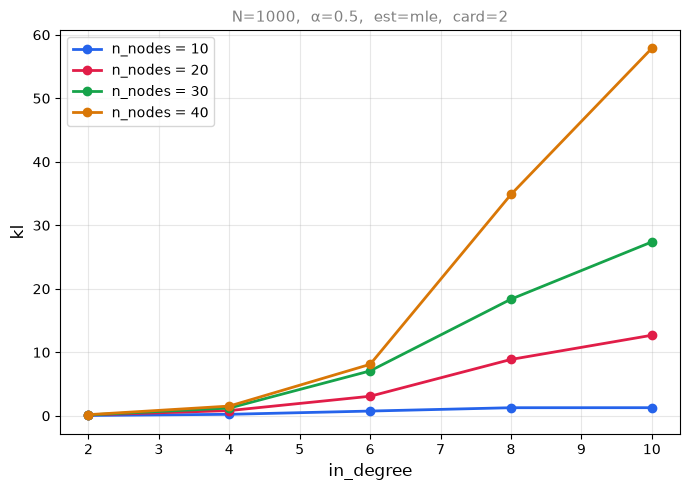

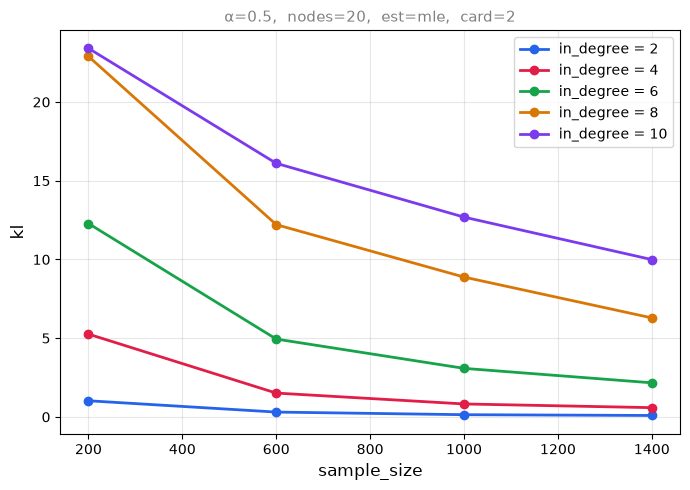

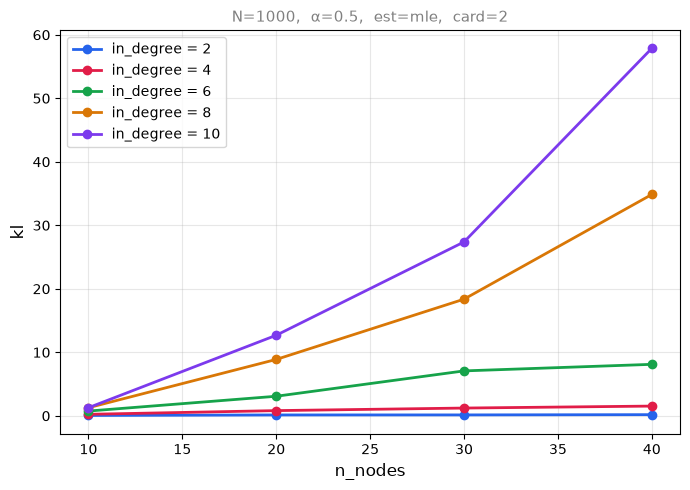

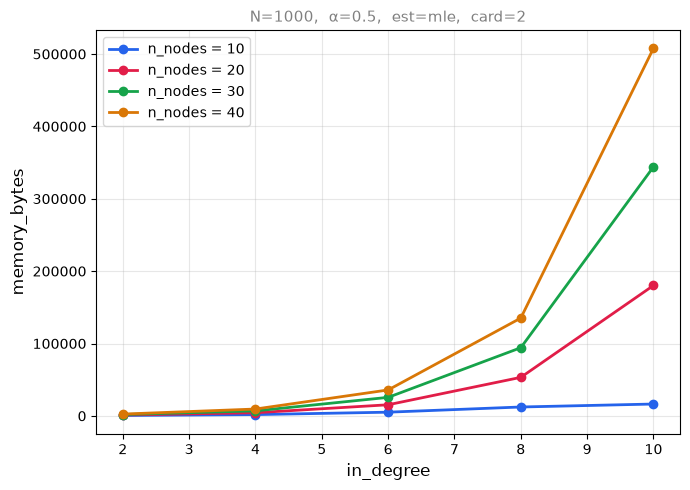

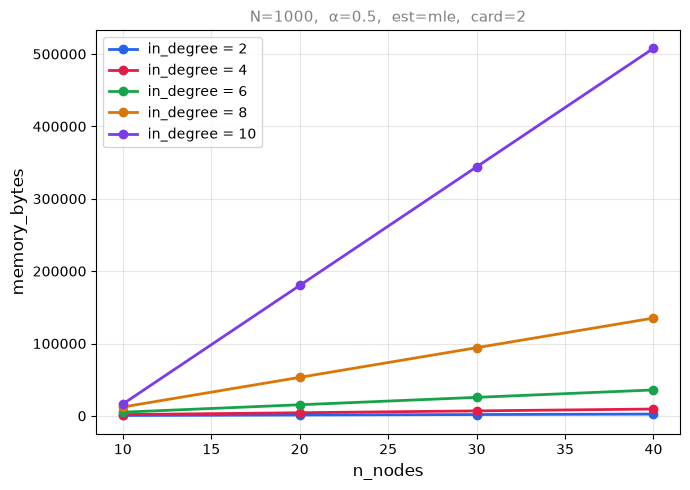

In [19]:
df = pd.read_csv(RESULTS_CSV)

plot_dir = os.path.join(RESULTS_DIR, "plots")
os.makedirs(plot_dir, exist_ok=True)

plot_grouped_curves(df, x="in_degree", hue="n_nodes", y="kl", out_path="kl_vs_indegree_by_n_nodes.png")
plot_grouped_curves(df, x="sample_size", hue="in_degree", y="kl", n_nodes=20, out_path="kl_vs_samplesize.png")
plot_grouped_curves(df, x="n_nodes", hue="in_degree", y="kl", out_path="kl_vs_networksize.png")
plot_grouped_curves(df, x="in_degree", hue="n_nodes", y="memory_bytes", out_path="memory_vs_indegree")
plot_grouped_curves(df, x="n_nodes", hue="in_degree", y="memory_bytes", out_path="memory_vs_n_nodes")
#plot_cardinality_wall(cards=(2,3,4,5), max_k=14, wall_bytes=8*1024**3, out_path="fig4.png")

(<Figure size 700x500 with 1 Axes>,
 <Axes: title={'center': 'N=1000,  α=0.5,  nodes=20,  card=2'}, xlabel='in_degree', ylabel='stored_params'>)

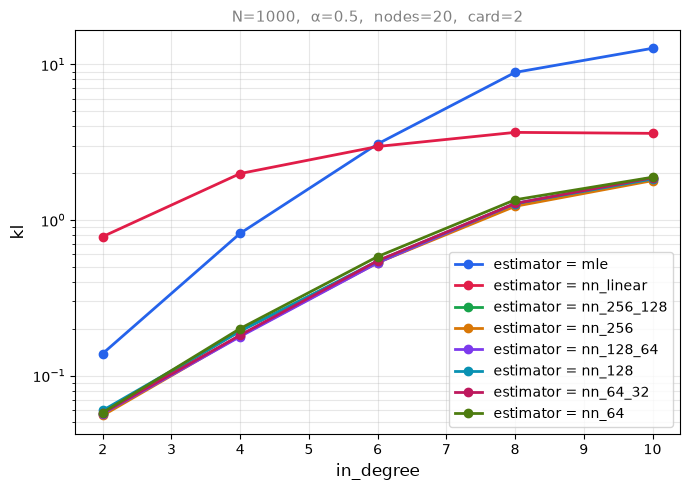

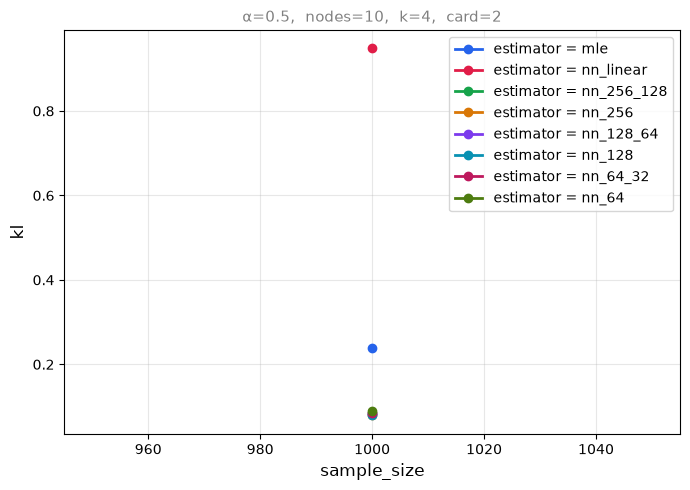

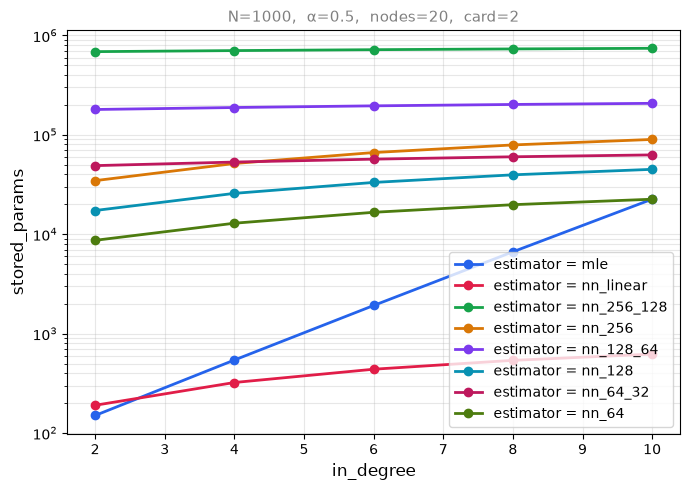

In [11]:
plot_grouped_curves(df, x="in_degree",   hue="estimator", y="kl", logy=True)
plot_grouped_curves(df, x="sample_size", hue="estimator", y="kl", n_nodes=10)
plot_grouped_curves(df, x="in_degree",   hue="estimator", y="stored_params", logy=True)

### Timing run (serial)
Training-time results come only from here: serial (`n_jobs=1`), fixed device and threads, the same
`SIM` DAGs per config as the main run (timings averaged over them), α = 0.5 only (training time
barely depends on α, and the timing plots use α = 0.5). Written to its own `results_timing.csv`
(same cached data). Run it on an otherwise idle machine, with no other notebooks or sweeps running.

In [10]:
run_experiments(
    node_counts=NODE_COUNTS, in_degrees=IN_DEGREES, n_dags=SIM,
    alphas=[0.5],          # time barely depends on alpha; the timing plots use 0.5
    sample_sizes=SAMPLE_SIZES, estimators=ESTIMATORS, card=CARD,
    val_frac=VAL_FRAC, n_test=N_TEST, n_epochs=N_EPOCHS,
    results_dir=RESULTS_DIR, verbose=VERBOSE, results_name="results_timing.csv",
    n_jobs=1, device=DEVICE_OVERRIDE, torch_threads=TORCH_THREADS,
)

DAGs:   0%|          | 0/100 [00:00<?, ?it/s]

c:\Users\Kaylin\Documents\Neural-Discrete-Bayesian-Network\ndbn\models.py:66: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  idx = torch.as_tensor(data[parents].to_numpy(np.int64), device=DEVICE)


KeyboardInterrupt: 

### Training time
From the serial timing run above (parallel timings are inflated).

In [ ]:
# training time only from the serial timing run (parallel timings are inflated)
if os.path.exists(TIMING_CSV):
    timing = pd.read_csv(TIMING_CSV)
    # one figure per estimator: time vs in-degree, a line per network size
    for est in ESTIMATORS:
        plot_grouped_curves(timing, x="in_degree", hue="n_nodes", y="fit_time_s",
                            estimator=est["name"], alpha=0.5,
                            title=f"training time: {est['name']}",
                            out_path=f"training_time_{est['name']}.png")
    # all estimators at one network size; log scale (MLE ~0.1 s, NNs ~20 s)
    plot_grouped_curves(timing, x="in_degree", hue="estimator", y="fit_time_s",
                        n_nodes=20, alpha=0.5, logy=True,
                        title="training time by estimator",
                        out_path="training_time_by_estimator.png")
else:
    print("no timing run yet: run the timing cell to make the training_time_*.png plots")